In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
import numpy as np
from dataset import build_cycle_bounded_windows

## 1. Training Dilated TCN Autoencoder on multivariate time series

In [4]:
from train import train_and_evaluate

train_and_evaluate(csv_path='../Dataset/FF_Multimodal.csv', epochs=50)

=== STARTING TCN TRAINING (WCE CLASSIFICATION + SENSOR MSE) [Device: cpu] ===


/home/leviathan/LastThesis/Repository/train.py:294: DtypeWarning: Columns (47: Description) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


Train windows: (117924, 20, 64) | Val windows: (29837, 20, 64)
Computed Class Rarity Weights (Classes 0..6): [ 0.282  1.125 50.    19.231  0.832 19.408  0.799]
Epoch 01/50 | Train [Total: 0.8247 | Sensor MSE: 0.2557 | Label WCE: 0.5690] | Val [Total: 0.5054 | Sensor MSE: 0.1861 | Label WCE: 0.3193] | Weighted F1: 0.8814
Epoch 02/50 | Train [Total: 0.5489 | Sensor MSE: 0.1915 | Label WCE: 0.3574] | Val [Total: 0.4450 | Sensor MSE: 0.1716 | Label WCE: 0.2734] | Weighted F1: 0.8920
Epoch 03/50 | Train [Total: 0.4862 | Sensor MSE: 0.1761 | Label WCE: 0.3101] | Val [Total: 0.4143 | Sensor MSE: 0.1624 | Label WCE: 0.2518] | Weighted F1: 0.9014
Epoch 04/50 | Train [Total: 0.4490 | Sensor MSE: 0.1674 | Label WCE: 0.2815] | Val [Total: 0.4124 | Sensor MSE: 0.1554 | Label WCE: 0.2570] | Weighted F1: 0.9043
Epoch 05/50 | Train [Total: 0.4292 | Sensor MSE: 0.1615 | Label WCE: 0.2676] | Val [Total: 0.4297 | Sensor MSE: 0.1532 | Label WCE: 0.2764] | Weighted F1: 0.8985
Epoch 06/50 | Train [Total: 0.

## 2. Plotting the training/validation log

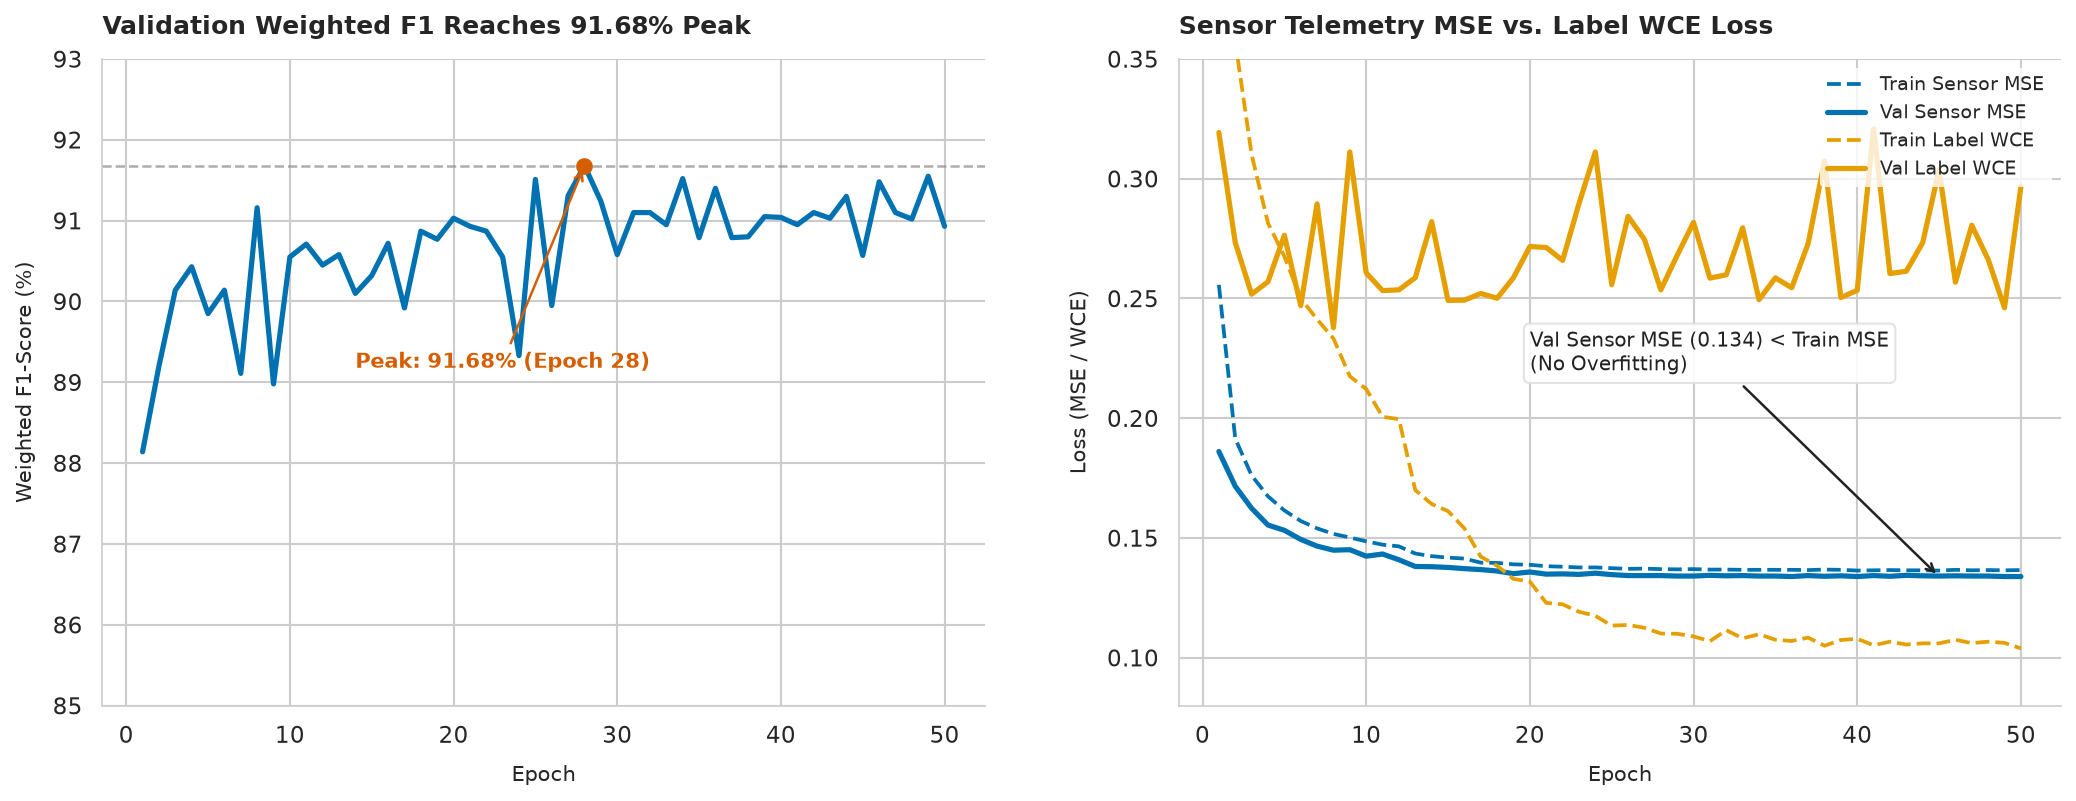

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Set clean seaborn theme & font styling
sns.set_theme(style='whitegrid', font='sans-serif')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# 2. Colorblind-safe palette (Okabe-Ito hex values)
COLOR_BLUE = '#0072B2'   # Primary metric / Val Sensor MSE
COLOR_ORANGE = '#E69F00' # Val Label WCE
COLOR_RED = '#D55E00'    # Peak highlights
COLOR_REF = '#8A8A8A'    # Reference lines

# 3. Load training log dataset (update path if needed)
log_path = './experiments/sensor_autoencoder/tcn_autoencoder_training_log_50_epochs.csv'
df = pd.read_csv(log_path)

# 4. Create 1x2 Subplot Grid
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)


# SUBPLOT 1: Validation Weighted F1-Score
ax1.plot(
    df['epoch'],
    df['val_weighted_f1'] * 100,
    color=COLOR_BLUE,
    linewidth=2.5,
    label='Validation Weighted F1'
)

# Reference line for Peak F1
ax1.axhline(91.68, color=COLOR_REF, linestyle='--', linewidth=1.2, alpha=0.7)

# Highlight Peak F1 at Epoch 28
peak_epoch = 28
peak_f1 = 91.68
ax1.plot(peak_epoch, peak_f1, 'o', color=COLOR_RED, markersize=7)
ax1.annotate(
    f'Peak: {peak_f1:.2f}% (Epoch {peak_epoch})',
    xy=(peak_epoch, peak_f1),
    xytext=(peak_epoch - 14, peak_f1 - 2.5),
    arrowprops=dict(arrowstyle='->', color=COLOR_RED, lw=1.2),
    fontsize=10,
    fontweight='bold',
    color=COLOR_RED
)

ax1.set_title('Validation Weighted F1 Reaches 91.68% Peak', fontsize=12, fontweight='bold', pad=12, loc='left')
ax1.set_xlabel('Epoch', fontsize=10, labelpad=8)
ax1.set_ylabel('Weighted F1-Score (%)', fontsize=10, labelpad=8)
ax1.set_ylim(85, 93)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)


# SUBPLOT 2: Decomposed Multi-Task Loss
ax2.plot(
    df['epoch'],
    df['train_sensor_mse'],
    color=COLOR_BLUE,
    linestyle='--',
    linewidth=1.8,
    label='Train Sensor MSE'
)
ax2.plot(
    df['epoch'],
    df['val_sensor_mse'],
    color=COLOR_BLUE,
    linewidth=2.5,
    label='Val Sensor MSE'
)
ax2.plot(
    df['epoch'],
    df['train_label_wce'],
    color=COLOR_ORANGE,
    linestyle='--',
    linewidth=1.8,
    label='Train Label WCE'
)
ax2.plot(
    df['epoch'],
    df['val_label_wce'],
    color=COLOR_ORANGE,
    linewidth=2.5,
    label='Val Label WCE'
)

# Annotate Validation Sensor MSE stability
ax2.annotate(
    'Val Sensor MSE (0.134) < Train MSE\n(No Overfitting)',
    xy=(45, 0.1339),
    xytext=(20, 0.22),
    arrowprops=dict(arrowstyle='->', color='#222222', lw=1.2),
    fontsize=9.5,
    color='#222222',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#E0E0E0', alpha=0.9)
)

ax2.set_title('Sensor Telemetry MSE vs. Label WCE Loss', fontsize=12, fontweight='bold', pad=12, loc='left')
ax2.set_xlabel('Epoch', fontsize=10, labelpad=8)
ax2.set_ylabel('Loss (MSE / WCE)', fontsize=10, labelpad=8)
ax2.set_ylim(0.08, 0.35)
ax2.legend(loc='upper right', frameon=True, facecolor='white', edgecolor='none', fontsize=9)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# 5. Final adjustments and display/save
plt.tight_layout()
plt.subplots_adjust(wspace=0.22)
plt.savefig('tcn_training_performance.png', dpi=300, bbox_inches='tight')
plt.show()